# Assignment 4 

# Task 1: Basketball Game Commentary Analysis

## I used ollama desktop because the ollama docker container was not working and on returned errors.

In [233]:
import ollama

# Test connection to Ollama Desktop
print("Testing Ollama Desktop connection...")

try:
    # List available models
    models = ollama.list()
    
    print("✓ Connected to Ollama Desktop!")
    print(f"Available models: {len(models.get('models', []))}")
    
    if models.get('models'):
        for model in models['models']:
            model_name = model.get('name', 'Unknown')
            print(f"  - {model_name}")
        
        # Quick test with first model
        test_model = models['models'][0].get('name', 'llama3.2')
        print(f"Testing {test_model}...")
        
        try:
            response = ollama.chat(
                model=test_model,
                messages=[{'role': 'user', 'content': 'Respond with exactly: "Ready!"'}]
            )
            print(f"Response: {response['message']['content']}")
            print("✓✓ Ollama Desktop is working!")
        except Exception as test_error:
            print(f"Model test failed: {test_error}")
            print("But connection is established.")
        
    else:
        print("⚠️ No models installed!")
        print("In PowerShell, run:")
        print("  ollama pull llama3.2")
        
except Exception as e:
    print(f"❌ Cannot connect to Ollama Desktop")
    print(f"Error: {e}")
    print("Troubleshooting:")
    print("1. Make sure Ollama Desktop is installed and running")
    print("2. Check system tray for Ollama icon")
    print("3. Restart terminal and try: ollama pull llama3.2")
    print("4. If 'ollama' command not found, restart your computer")


Testing Ollama Desktop connection...
✓ Connected to Ollama Desktop!
Available models: 1
  - Unknown
Testing llama3.2...
Response: Ready!
✓✓ Ollama Desktop is working!


## Setup: Ollama Desktop Connection

**Prerequisites**: 
1. Install Ollama Desktop from https://ollama.com/download
2. Open PowerShell and run: `ollama pull llama3.2`
3. Verify with: `ollama list`

Run the cell below to test the connection:

In [234]:
import os

# Fix for Windows symlink permission error
# This tells Hugging Face to download full files instead of creating symlinks
os.environ['HF_HUB_DISABLE_SYMLINKS'] = '1'

print("✓ Disabled symlinks for Hugging Face downloads")
print("  (This fixes 'WinError 1314' permission errors on Windows)")
print("\nYou can now run the transcription cell without admin privileges!")

✓ Disabled symlinks for Hugging Face downloads
  (This fixes 'WinError 1314' permission errors on Windows)

You can now run the transcription cell without admin privileges!


## Fix for Windows Symlink Error

Run this cell to fix the "WinError 1314" symlink permission error:

In [235]:
## Automatic Video Verification Examples
## When you ask about a player, video clips and diagrams are shown automatically!

# Example 1: Ask about LeBron James
# qa_system.ask("How did LeBron James perform in this game?")

# Example 2: Ask about specific actions
# qa_system.ask("What three-point shots did Stephen Curry make?")

# Example 3: Ask about scoring
# qa_system.ask("How many points did Anthony Davis score?")

# Example 4: General player query
# qa_system.ask("Tell me about Klay Thompson's performance")

## Manual verification (if needed):
# answer_with_verification("LeBron James", max_clips=5)


## Task 1 + Task 2 Integration: Automatic Video Verification

When you ask about a player using the QA system, it will **automatically**:
1. Answer your question from commentary (Task 1)
2. Detect the player name from your question
3. Extract video clips showing that player (Task 2)
4. Generate bird's eye court diagrams (Task 2)
5. Display everything together

**No need to call a separate function!** Just ask your question:

```python
# These will automatically trigger video verification:
qa_system.ask("How did LeBron James perform?")
qa_system.ask("What three-point shots did Stephen Curry make?")
qa_system.ask("How many points did Anthony Davis score?")
```

The system detects player names and automatically shows:
- Commentary-based answer
- Video clips at relevant timestamps
- Bird's eye court diagrams
- All integrated together!

**Manual Usage (Optional):**
If you want to call verification separately:
```python
answer_with_verification("Player Name", ["keyword"], max_clips=3)
```


In [236]:
def answer_with_verification(player_name: str, action_keywords: list = None, max_clips: int = 3):
    """
    Answer question about player with commentary + video verification
    
    This implements the Task 1 + Task 2 integration:
    1. Query Task 1 (commentary) for player mentions
    2. Extract mentioned actions and timestamps  
    3. For each action, show Task 2 (video clip + diagram with YOLO detection)
    
    Args:
        player_name: Player to analyze (e.g., "LeBron James")
        action_keywords: Optional keywords to filter (e.g., ["three", "shot"])
        max_clips: Maximum number of clips to show (default 3)
    """
    print(f"\n{'='*80}")
    print(f"ANALYZING: {player_name}")
    print(f"{'='*80}\n")
    
    # ========== TASK 1: Commentary Analysis ==========
    print("📝 TASK 1: Commentary-Based Analysis")
    print("-" * 80)
    
    # Load transcription
    try:
        with open('transcription.json', 'r') as f:
            transcription = json.load(f)
    except FileNotFoundError:
        print("⚠️ transcription.json not found. Run Task 1 first!")
        return
    
    # Find mentions of the player
    player_mentions = []
    for segment in transcription.get('segments', []):
        text = segment.get('text', '')
        if player_name.lower() in text.lower():
            timestamp = segment.get('start', 0)
            mins = int(timestamp // 60)
            secs = int(timestamp % 60)
            player_mentions.append({
                'timestamp': f"{mins:02d}:{secs:02d}",
                'timestamp_seconds': timestamp,
                'text': text.strip()
            })
    
    if not player_mentions:
        print(f"❌ No mentions of {player_name} found in commentary")
        return
    
    # Filter by action keywords if provided
    if action_keywords:
        filtered = []
        for mention in player_mentions:
            if any(keyword.lower() in mention['text'].lower() for keyword in action_keywords):
                filtered.append(mention)
        player_mentions = filtered
    
    print(f"✓ Found {len(player_mentions)} relevant commentary mentions\n")
    for i, mention in enumerate(player_mentions[:10], 1):  # Show first 10
        print(f"{i}. [{mention['timestamp']}] {mention['text']}")
    
    # ========== TASK 2: Video Verification ==========
    if not VIDEO_AVAILABLE:
        print("\n⚠️ Video not available. Skipping Task 2 verification.")
        return
    
    print(f"\n{'='*80}")
    print("🎥 TASK 2: Video Verification with YOLO Player Detection")
    print("-" * 80)
    
    # Create output directories
    clips_dir = TASK2_OUTPUT / "video_clips"
    diagrams_dir = TASK2_OUTPUT / "diagrams"
    clips_dir.mkdir(exist_ok=True)
    diagrams_dir.mkdir(exist_ok=True)
    
    print(f"📁 Saving outputs to: {TASK2_OUTPUT}")
    print(f"  - Video clips: {clips_dir}")
    print(f"  - Diagrams: {diagrams_dir}")
    
    extractor = VideoClipExtractor(VIDEO_PATH)
    court = BasketballCourtDiagram()
    
    # Process mentions
    num_clips = min(max_clips, len(player_mentions))
    for i, mention in enumerate(player_mentions[:num_clips], 1):
        print(f"\n{'─'*60}")
        print(f"Verification {i}/{num_clips}")
        print(f"{'─'*60}")
        print(f"⏰ Timestamp: {mention['timestamp']}")
        print(f"💬 Commentary: {mention['text']}")
        print()
        
        # Create video clip
        clip_filename = f"{player_name.replace(' ', '_')}_{mention['timestamp'].replace(':', '_')}.mp4"
        clip_path = clips_dir / clip_filename
        extractor.extract_clip(mention['timestamp'], duration=10, output_path=str(clip_path))
        
        # Create bird's eye diagram
        diagram_filename = f"{player_name.replace(' ', '_')}_{mention['timestamp'].replace(':', '_')}.png"
        diagram_path = diagrams_dir / diagram_filename

        # Determine player team colors
        lakers_players = ["LeBron", "James", "Davis", "Anthony Davis", "LeBron James", "Kuzma", "Kyle Kuzma", 
                         "Harrell", "Montrezl Harrell", "Schroder", "Dennis Schroder", "Gasol", "Marc Gasol", 
                         "Drummond", "Andre Drummond", "Matthews", "Wesley Matthews"]
        warriors_players = ["Curry", "Stephen Curry", "Thompson", "Klay Thompson", "Green", "Draymond Green",
                           "Bell", "Jordan Bell", "Poole", "Jordan Poole", "Looney", "Kevon Looney",
                           "Bazemore", "Kent Bazemore", "Lee", "Damion Lee"]

        player_is_lakers = any(p.lower() in player_name.lower() for p in lakers_players)
        player_color = "#552583" if player_is_lakers else "#FDB927"  # Lakers purple or Warriors gold
        opponent_color = "#FDB927" if player_is_lakers else "#552583"

        print(f"🔍 Running YOLO detection across multiple frames...")
        
        # Use multi-frame detection for better accuracy
        detected_players = extractor.detect_players_in_clip(mention["timestamp"], duration=10, sample_rate=5)

        if detected_players and len(detected_players) >= 2:
            print(f"✓ Using YOLO-detected positions for {len(detected_players)} players")
            
            # Use detected player positions
            court_players = []
            for idx, det in enumerate(detected_players[:10]):  # Max 10 players
                # Assign colors: assume first 5 are one team, next 5 are other team
                color = player_color if idx < 5 else opponent_color
                label = player_name.split()[-1] if idx == 0 else f"P{idx+1}"
                has_ball = (idx == 0)  # Assume player of interest has ball

                court_players.append({
                    "x": det["x"],
                    "y": det["y"],
                    "label": label,
                    "color": color,
                    "has_ball": has_ball
                })
        else:
            print(f"⚠️ Falling back to representative 5v5 positions")
            
            # Fallback: create 5v5 representative positions
            court_players = [
                # Team 1 (5 players)
                {"x": 70, "y": 25, "label": player_name.split()[-1], "color": player_color, "has_ball": True},
                {"x": 60, "y": 35, "label": "T1", "color": player_color},
                {"x": 80, "y": 20, "label": "T2", "color": player_color},
                {"x": 55, "y": 15, "label": "T3", "color": player_color},
                {"x": 75, "y": 40, "label": "T4", "color": player_color},
                # Team 2 (5 players)
                {"x": 68, "y": 28, "label": "O1", "color": opponent_color},
                {"x": 75, "y": 30, "label": "O2", "color": opponent_color},
                {"x": 65, "y": 18, "label": "O3", "color": opponent_color},
                {"x": 82, "y": 35, "label": "O4", "color": opponent_color},
                {"x": 70, "y": 45, "label": "O5", "color": opponent_color},
            ]

        # Create diagram
        court.create_diagram(
            players=court_players,
            title=f"{mention['timestamp']} - {player_name} ({len(court_players)} players detected)",
            save_path=str(diagram_path)
        )
        
        # Display
        print("\n📊 Bird's Eye View:")
        display(Image(filename=str(diagram_path)))
        
        print("\n🎥 Video Clip:")
        display(Video(str(clip_path), width=640, html_attributes="controls"))
    
    print(f"\n{'='*80}")
    print(f"✓ Analysis Complete")
    print(f"  - Commentary mentions: {len(player_mentions)}")
    print(f"  - Video clips created: {num_clips}")
    print(f"  - Diagrams created: {num_clips}")
    print(f"  - Output directory: {TASK2_OUTPUT}")
    
    # List all saved files
    print("📂 Saved Files:")
    all_clips = sorted(clips_dir.glob("*.mp4"))
    all_diagrams = sorted(diagrams_dir.glob("*.png"))
    for clip in all_clips[-num_clips:]:
        print(f"  📹 {clip.name}")
    for diagram in all_diagrams[-num_clips:]:
        print(f"  📊 {diagram.name}")
    print(f"{'='*80}\n")

print("✓ Integration function defined with YOLO multi-frame detection")
print("\n📖 Usage:")
print('   answer_with_verification("LeBron James")')
print('   answer_with_verification("Stephen Curry", ["three", "shot"])')

✓ Integration function defined with YOLO multi-frame detection

📖 Usage:
   answer_with_verification("LeBron James")
   answer_with_verification("Stephen Curry", ["three", "shot"])


In [237]:
class VideoClipExtractor:
    """Extract video clips for player actions"""
    
    def __init__(self, video_path: str):
        self.video_path = video_path
    
    def timestamp_to_seconds(self, timestamp: str) -> float:
        """Convert MM:SS to seconds"""
        parts = timestamp.split(':')
        if len(parts) == 2:
            return int(parts[0]) * 60 + float(parts[1])
        return float(timestamp)
    
    def extract_clip(self, timestamp: str, duration: int = 10, output_path: str = None):
        """
        Extract video clip around a timestamp
        
        Args:
            timestamp: Time in MM:SS format
            duration: Clip duration in seconds (default 10)
            output_path: Where to save the clip
        """
        center_time = self.timestamp_to_seconds(timestamp)
        start_time = max(0, center_time - duration/2)
        end_time = center_time + duration/2
        
        cap = cv2.VideoCapture(self.video_path)
        fps = cap.get(cv2.CAP_PROP_FPS)
        width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        
        # Set to start frame
        start_frame = int(start_time * fps)
        end_frame = int(end_time * fps)
        cap.set(cv2.CAP_PROP_POS_FRAMES, start_frame)
        
        # Create output
        fourcc = cv2.VideoWriter_fourcc(*'mp4v')
        out = cv2.VideoWriter(output_path, fourcc, fps, (width, height))
        
        # Extract frames
        current_frame = start_frame
        while current_frame <= end_frame:
            ret, frame = cap.read()
            if not ret:
                break
            out.write(frame)
            current_frame += 1
        
        cap.release()
        out.release()
        
        print(f"✓ Extracted {end_frame - start_frame} frames ({duration}s) → {output_path}")
        return output_path


    
    def detect_players_in_frame(self, timestamp: str):
        """
        Detect players in a video frame at the given timestamp using YOLO
        Returns list of player detections with positions
        """
        try:
            # Get the frame at timestamp
            center_time = self.timestamp_to_seconds(timestamp)
            cap = cv2.VideoCapture(self.video_path)
            fps = cap.get(cv2.CAP_PROP_FPS)
            frame_number = int(center_time * fps)
            cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)
            ret, frame = cap.read()
            cap.release()
            
            if not ret:
                print(f"⚠️ Could not read frame at {timestamp}")
                return []
            
            # Check if YOLO model is available
            if 'yolo_model' not in globals() or globals()['yolo_model'] is None:
                print("⚠️ YOLO model not available")
                return []
            
            # Run YOLO detection for persons (class 0)
            results = yolo_model(frame, classes=[0], verbose=False)
            
            players = []
            frame_height, frame_width = frame.shape[:2]
            
            # Convert detections to court coordinates
            # Basketball court: 94 feet (length) x 50 feet (width)
            for detection in results[0].boxes:
                x1, y1, x2, y2 = detection.xyxy[0].cpu().numpy()
                conf = detection.conf[0].cpu().numpy()
                
                if conf > 0.5:  # Confidence threshold
                    # Center of bounding box (feet position)
                    center_x = (x1 + x2) / 2
                    center_y = (y1 + y2) / 2
                    
                    # Map video coordinates to basketball court coordinates
                    # Assuming video shows full court view
                    court_x = (center_x / frame_width) * 94
                    court_y = (center_y / frame_height) * 50
                    
                    players.append({
                        'x': court_x,
                        'y': court_y,
                        'conf': float(conf),
                        'bbox': [float(x1), float(y1), float(x2), float(y2)]
                    })
            
            # Sort by y-coordinate (closer to camera = higher y value typically)
            players.sort(key=lambda p: p['y'], reverse=True)
            
            print(f"✓ Detected {len(players)} players at {timestamp}")
            return players[:10]  # Return max 10 players for 5v5
            
        except Exception as e:
            print(f"⚠️ Error detecting players: {e}")
            return []
    
    
    def detect_players_in_clip(self, timestamp: str, duration: int = 10, sample_rate: int = 5):
        """
        Detect players across multiple frames in a clip for better accuracy
        
        Args:
            timestamp: Center timestamp in MM:SS format
            duration: Clip duration in seconds
            sample_rate: Sample every Nth frame (5 = every 5th frame)
        
        Returns:
            Average player positions across sampled frames
        """
        try:
            center_time = self.timestamp_to_seconds(timestamp)
            start_time = max(0, center_time - duration/2)
            end_time = center_time + duration/2
            
            cap = cv2.VideoCapture(self.video_path)
            fps = cap.get(cv2.CAP_PROP_FPS)
            start_frame = int(start_time * fps)
            end_frame = int(end_time * fps)
            frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
            frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
            
            # Check if YOLO model is available
            if 'yolo_model' not in globals() or globals()['yolo_model'] is None:
                cap.release()
                print("⚠️ YOLO model not available")
                return []
            
            all_detections = []
            frame_count = 0
            
            # Sample frames throughout the clip
            for frame_num in range(start_frame, end_frame, sample_rate):
                cap.set(cv2.CAP_PROP_POS_FRAMES, frame_num)
                ret, frame = cap.read()
                if not ret:
                    continue
                
                # Run YOLO detection
                results = yolo_model(frame, classes=[0], verbose=False)
                
                for detection in results[0].boxes:
                    x1, y1, x2, y2 = detection.xyxy[0].cpu().numpy()
                    conf = detection.conf[0].cpu().numpy()
                    
                    if conf > 0.5:
                        center_x = (x1 + x2) / 2
                        center_y = (y1 + y2) / 2
                        
                        # Map to court coordinates
                        court_x = (center_x / frame_width) * 94
                        court_y = (center_y / frame_height) * 50
                        
                        all_detections.append({
                            'x': court_x,
                            'y': court_y,
                            'conf': float(conf)
                        })
                
                frame_count += 1
            
            cap.release()
            
            if not all_detections:
                print(f"⚠️ No players detected in clip at {timestamp}")
                return []
            
            # Cluster detections to find unique players
            # Simple approach: group nearby detections (within 10 feet)
            clustered_players = []
            used = [False] * len(all_detections)
            
            for i, det in enumerate(all_detections):
                if used[i]:
                    continue
                
                cluster = [det]
                used[i] = True
                
                for j in range(i + 1, len(all_detections)):
                    if used[j]:
                        continue
                    
                    # Check if detection is close to current cluster center
                    dist = ((det['x'] - all_detections[j]['x'])**2 + 
                           (det['y'] - all_detections[j]['y'])**2)**0.5
                    
                    if dist < 10:  # Within 10 feet
                        cluster.append(all_detections[j])
                        used[j] = True
                
                # Average the cluster to get player position
                avg_x = sum(d['x'] for d in cluster) / len(cluster)
                avg_y = sum(d['y'] for d in cluster) / len(cluster)
                avg_conf = sum(d['conf'] for d in cluster) / len(cluster)
                
                clustered_players.append({
                    'x': avg_x,
                    'y': avg_y,
                    'conf': avg_conf,
                    'detections': len(cluster)
                })
            
            # Sort by confidence and number of detections
            clustered_players.sort(key=lambda p: (p['detections'], p['conf']), reverse=True)
            
            print(f"✓ Detected {len(clustered_players)} unique players across {frame_count} frames at {timestamp}")
            return clustered_players[:10]  # Return top 10 for 5v5
            
        except Exception as e:
            print(f"⚠️ Error detecting players in clip: {e}")
            return []


print("✓ VideoClipExtractor class defined with enhanced YOLO detection")

✓ VideoClipExtractor class defined with enhanced YOLO detection


In [238]:
import cv2
import json
from pathlib import Path
from IPython.display import Image, Video, display

# Verify video path
VIDEO_PATH = r"C:\Users\rjwil\Downloads\Warriors & Lakers Instant Classic - 2021 Play-In Tournament 🔥_ NBA Classic Game.mp4"
VIDEO_AVAILABLE = Path(VIDEO_PATH).exists()

if VIDEO_AVAILABLE:
    print(f"✓ Video found: {VIDEO_PATH}")
    cap = cv2.VideoCapture(VIDEO_PATH)
    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_min = (total_frames / fps) / 60
    print(f"✓ Duration: {duration_min:.1f} minutes")
    print(f"✓ FPS: {fps:.2f}")
    cap.release()
else:
    print(f"⚠️ Video not found at: {VIDEO_PATH}")
    print("Task 2 video verification will be disabled")

✓ Video found: C:\Users\rjwil\Downloads\Warriors & Lakers Instant Classic - 2021 Play-In Tournament 🔥_ NBA Classic Game.mp4
✓ Duration: 94.0 minutes
✓ FPS: 29.97


# Assignment 4: BasketTube - AI-Powered Basketball Commentary Analysis

## Workflow

1. **Task 1**: Answer user questions from game commentary
2. **Task 2**: Verify answers with actual video evidence
   - **Task 2.1**: Segment video into plays
   - **Task 2.2**: Extract player actions with video clips + bird's eye diagrams

**Integration**: When answering user questions, provide commentary-based answer PLUS video verification (clips + diagrams)

# Task 1 + Task 2 Integration

This section integrates commentary analysis (Task 1) with video verification (Task 2).

**Workflow**: User asks question → Answer from commentary → Verify with video clips + diagrams

In [239]:
!pip install faster-whisper chromadb ollama sentence-transformers

In [240]:
import os
from faster_whisper import WhisperModel
import chromadb
import ollama
from sentence_transformers import SentenceTransformer
import subprocess
import json
from typing import List, Dict

## Step 3: Load and Extract Audio Portion

We'll load the MP3 file from the video folder and extract a 20-30 minute portion using ffmpeg.

In [241]:
## This function takes the input path of the entire mp3 file, and creates a new mp3 file that is a fraction of the duration (I didn't want to embed the entire hour and a half long game)
def extract_audio_portion(
    input_path: str, 
    output_path: str, 
    start_minutes: int = 0, 
    duration_minutes: int = 25
) -> str:
    ## Convert to seconds for ffmpeg
    start_seconds = start_minutes * 60
    duration_seconds = duration_minutes * 60
    
    ## Build ffmpeg command - re-encode to MP3 since source is AAC in MP4 container
    command = [
        'ffmpeg',
        '-y', ## Overwrite output file if exists
        '-i', input_path,
        '-ss', str(start_seconds),
        '-t', str(duration_seconds),
        '-acodec', 'libmp3lame', ## Re-encode to MP3
        '-q:a', '2',
        output_path
    ]
    
    print(f"Extracting {duration_minutes} minutes starting at {start_minutes} min...")
    result = subprocess.run(command, capture_output=True, text=True)
    
    if result.returncode != 0:
        print(f"ffmpeg error: {result.stderr}")
        raise RuntimeError("Failed to extract audio portion")
    
    print(f"Extracted audio saved to: {output_path}")
    return output_path

In [242]:
import os

## Path to the source MP3 file
SOURCE_AUDIO = "video/video.mp3"
OUTPUT_FILE = "game_portion.mp3"

# Check if the extracted file already exists
if os.path.exists(OUTPUT_FILE):
    audio_path = OUTPUT_FILE
    print(f"✓ Using existing file: {OUTPUT_FILE}")
elif os.path.exists(SOURCE_AUDIO):
    audio_path = SOURCE_AUDIO
    print(f"⚠️ Using full audio file: {SOURCE_AUDIO}")
else:
    print(f"❌ No audio file found!")
    audio_path = None

if audio_path:
    print(f"\nUsing audio file: {audio_path}")

✓ Using existing file: game_portion.mp3

Using audio file: game_portion.mp3


In [243]:
## This function transcribes the audio file and adds timestamps with them 
def transcribe_with_timestamps(audio_path: str, model_size: str = "small") -> Dict:

    print(f"Loading Faster-Whisper model: {model_size}")
    
    ## Specification of whisper model that is being used
    model = WhisperModel(model_size, device="cpu", compute_type="int8")
    
    print(f"Transcribing: {audio_path}")
    print("This may take several minutes...")
    
    ## Transcribe with word timestamps
    segments, info = model.transcribe(
        audio_path,
        word_timestamps=True,
        vad_filter=True ## Filter out silence
    )
    
    print(f"Detected language: {info.language} (probability: {info.language_probability:.2f})")
    
    ## Convert generator to list and format
    segments_list = []
    full_text = []
    
    for segment in segments:
        segments_list.append({
            'id': segment.id,
            'start': segment.start,
            'end': segment.end,
            'text': segment.text.strip()
        })
        full_text.append(segment.text)
        print(f"[{segment.start:.2f}s -> {segment.end:.2f}s] {segment.text.strip()}")
    
    print(f"\nTranscription complete. Found {len(segments_list)} segments.")
    
    return {
        'text': ' '.join(full_text),
        'segments': segments_list,
        'language': info.language
    }

## This function changes the format of the timestamps to be in minutes and seconds and takes time in seconds as input
def format_timestamp(seconds: float) -> str:

    minutes = int(seconds // 60)
    secs = int(seconds % 60)
    return f"{minutes:02d}:{secs:02d}"

## This function processes the transcription segments into structured chucks so they are ready for the embedding process (these have the timestamps with them)
def process_segments(transcription: Dict) -> List[Dict]:
 
    processed = []
    
    for segment in transcription['segments']:
        processed.append({
            'id': segment['id'],
            'start': segment['start'],
            'end': segment['end'],
            'start_formatted': format_timestamp(segment['start']),
            'end_formatted': format_timestamp(segment['end']),
            'text': segment['text']
        })
    
    return processed

In [244]:
## using a different model_size would increase the accuracy, but it would take a really long time (I have 8GB of RAM)
transcription = transcribe_with_timestamps(audio_path, model_size="small")

## Process segments
segments = process_segments(transcription)

## Make sure that the segments are structured correctly.
print("\nFirst 5 segments:")
for seg in segments[:5]:
    print(f"[{seg['start_formatted']} - {seg['end_formatted']}]: {seg['text']}")

Loading Faster-Whisper model: small
Transcribing: game_portion.mp3
This may take several minutes...
Detected language: en (probability: 0.99)
[0.02s -> 1.30s] Well, it's not breaking news.
[1.48s -> 2.86s] They're a different basketball team
[2.86s -> 4.50s] with a healthy whole, LeBron James.
[5.74s -> 8.08s] 15 games over 500 when he's healthy.
[8.48s -> 9.90s] Three games under 500.
[10.50s -> 12.70s] Creakes offense for himself and his teammates.
[13.38s -> 13.86s] They need him.
[14.44s -> 16.34s] They all, Jeff, Steph Curry, what he's
[16.34s -> 17.98s] done over the past month and a half
[17.98s -> 19.58s] has been absolutely brilliant.
[20.08s -> 22.62s] He's as valuable as any player in this league.
[23.06s -> 25.02s] They play great defense, and they
[25.02s -> 26.92s] have the ultimate home run hitter.
[27.62s -> 30.52s] Well, beneath the team, it hasn't been easy this season,
[31.00s -> 33.62s] but both finished up the regular season strong.
[33.92s -> 36.00s] The Lakers en

In [245]:
class CommentaryVectorStore:

    ## Initialization of the vector storage class
    def __init__(self, collection_name: str = "basketball_commentary"):

        ## Initialize embedding model
        self.embedding_model = SentenceTransformer('all-MiniLM-L6-v2')
        
        ## Initialize ChromaDB
        self.client = chromadb.Client()
        
        ## Delete existing collection if it exists
        try:
            self.client.delete_collection(collection_name)
        except:
            pass
        
        self.collection = self.client.create_collection(
            name=collection_name,
            metadata={"hnsw:space": "cosine"}
        )
        
        print(f"Initialized vector store: {collection_name}")
    
    ## Add the transcription segments into the vectore storage.
    def add_segments(self, segments: List[Dict]) -> None:

        ## Group segments into larger chunks for better context
        chunks = self._create_chunks(segments, chunk_size=5)
        
        documents = []
        embeddings = []
        metadatas = []
        ids = []
        
        for i, chunk in enumerate(chunks):
            ## Combine text from segments in chunk
            text = " ".join([seg['text'] for seg in chunk])
            
            ## Get embedding
            embedding = self.embedding_model.encode(text).tolist()
            
            ## Metadata with timestamps
            metadata = {
                'start_time': chunk[0]['start'],
                'end_time': chunk[-1]['end'],
                'start_formatted': chunk[0]['start_formatted'],
                'end_formatted': chunk[-1]['end_formatted'],
                'segment_ids': ','.join([str(seg['id']) for seg in chunk])
            }
            
            documents.append(text)
            embeddings.append(embedding)
            metadatas.append(metadata)
            ids.append(f"chunk_{i}")
        
        ## Add to collection
        self.collection.add(
            documents=documents,
            embeddings=embeddings,
            metadatas=metadatas,
            ids=ids
        )
        
        print(f"Added {len(chunks)} chunks to vector store")
    
    ## This function groups the segments into larger chunks
    def _create_chunks(self, segments: List[Dict], chunk_size: int = 5) -> List[List[Dict]]:

        chunks = []
        for i in range(0, len(segments), chunk_size):
            chunk = segments[i:i + chunk_size]
            if chunk:
                chunks.append(chunk)
        return chunks
    
    ## This function searches for the relevant commentary chunks based on the users query returns the n_results number of relevant chunks
    def search(self, query: str, n_results: int = 5) -> List[Dict]:

        ## Get query embedding
        query_embedding = self.embedding_model.encode(query).tolist()
        
        ## Search
        results = self.collection.query(
            query_embeddings=[query_embedding],
            n_results=n_results,
            include=['documents', 'metadatas', 'distances']
        )
        
        ## Format results
        formatted = []
        for i in range(len(results['documents'][0])):
            formatted.append({
                'text': results['documents'][0][i],
                'metadata': results['metadatas'][0][i],
                'similarity': 1 - results['distances'][0][i]  # Convert distance to similarity
            })
        
        return formatted

In [246]:
## Initialize vector store and add segments
vector_store = CommentaryVectorStore()
vector_store.add_segments(segments)

## Test search
test_results = vector_store.search("three point shot", n_results=3)
print("\nTest search for 'three point shot':")
for result in test_results:
    print(f"\n[{result['metadata']['start_formatted']} - {result['metadata']['end_formatted']}]")
    print(f"Similarity: {result['similarity']:.3f}")
    print(f"Text: {result['text'][:200]}...")

Initialized vector store: basketball_commentary
Added 124 chunks to vector store

Test search for 'three point shot':

[22:46 - 22:59]
Similarity: 0.570
Text: in terms of taking some steps. But the three-pointer has been at times a struggle for him. Nice shot there, and it's a three-point game. Jordan Poole the floater. Looney's follow misses....

[06:25 - 06:32]
Similarity: 0.519
Text: Shocklock down a three. James a three-pointer. Way off. And Raymond bringing the rebound. The Lakers have missed nine of their first 11...

[18:27 - 18:39]
Similarity: 0.502
Text: Lakers shooting just 32% from the field, but they're only down by three. Montrez-Harrell spins, flips it up, shot won't go. Tipped by Kuzma and another offensive rebound,...


In [247]:
class BasketballCommentaryQA:

    ## Initialization of the Q&A commentary system
    def __init__(self, vector_store: CommentaryVectorStore, model: str = "llama3.2"):
        """
        Initialize the Q&A system.
        
        Args:
            vector_store: Vector store with commentary chunks
            model: Ollama model to use
        """
        self.vector_store = vector_store
        self.model = model
        
        ## System prompt for the LLM
        self.system_prompt = """You are an expert basketball analyst assistant. Your task is to analyze basketball game commentary and provide detailed insights about player performance.

IMPORTANT GUIDELINES:
1. Always reference specific timestamps when discussing events (format: MM:SS)
2. Provide structured analysis with clear sections
3. Include specific details from the commentary
4. Identify key plays, scoring moments, and performance trends
5. Be objective and analytical in your assessments

When analyzing player performance:
- Identify scoring plays and their timestamps
- Note defensive contributions
- Track momentum shifts
- Highlight key moments in the game

Format your response with:
- A summary section
- Detailed analysis with timestamps
- Key highlights

Note: All analysis is based on the commentary provided"""
    
    ## This function takes in a user prompt and returns an answer with timestamps
    def ask(self, question: str, n_context: int = 8) -> str:

        ## Retrieve relevant context
        context_results = self.vector_store.search(question, n_results=n_context)
        
        ## Build context string with timestamps
        context_parts = []
        for result in context_results:
            timestamp = f"[{result['metadata']['start_formatted']} - {result['metadata']['end_formatted']}]"
            context_parts.append(f"{timestamp}\n{result['text']}")
        
        context_string = "\n\n".join(context_parts)
        
        ## Build the prompt
        user_prompt = f"""Based on the following basketball game commentary, please answer this question:

QUESTION: {question}

COMMENTARY CONTEXT (with timestamps):
{context_string}

Please provide a detailed analysis with specific timestamp references."""
        
        ## Call Ollama
        response = ollama.chat(
            model=self.model,
            messages=[
                {"role": "system", "content": self.system_prompt},
                {"role": "user", "content": user_prompt}
            ]
        )

        # Auto-detect player and trigger video verification
        answer_text = response["message"]["content"]
        
        # Common player names - expanded list
        player_names = [
            "LeBron James", "Anthony Davis", "Stephen Curry", "Klay Thompson",
            "Draymond Green", "Kent Bazemore", "Kyle Kuzma", "Wesley Matthews",
            "Jordan Bell", "Jordan Poole", "Kevon Looney", "Damion Lee",
            "Montrezl Harrell", "Dennis Schroder", "Marc Gasol", "Andre Drummond",
            "LeBron", "Davis", "Curry", "Thompson", "Green", "Bazemore", "Kuzma",
            "Bell", "Poole", "Looney", "Harrell", "Schroder", "Gasol", "Drummond"
        ]
        
        # Detect player from question
        detected_player = None
        question_lower = question.lower()
        for player in player_names:
            if player.lower() in question_lower:
                detected_player = player
                break
        
        # Auto-trigger video verification
        if detected_player and VIDEO_AVAILABLE:
            print()
            print("=" * 80)
            print(f"AUTO-VERIFICATION: Detected query about {detected_player}")
            print("=" * 80)
            print()
            
            try:
                # Extract keywords
                keywords = []
                if "three" in question_lower or "3-point" in question_lower:
                    keywords.append("three")
                if "score" in question_lower or "basket" in question_lower:
                    keywords.append("score")
                if "defense" in question_lower or "block" in question_lower:
                    keywords.append("defense")
                
                # Call verification
                answer_with_verification(
                    detected_player,
                    action_keywords=keywords if keywords else None,
                    max_clips=3
                )
            except Exception as e:
                print(f"ERROR in video verification: {e}")
                import traceback
                traceback.print_exc()

        return response["message"]["content"]


        
        
        
            
                


    
    ## This function creates a chat that the user can interact with that answers questions with context and continues to ask questions until the user types 'quit'
    def interactive_chat(self):
        print("\n" + "="*60)
        print("Basketball Commentary Analysis System")
        print("="*60)
        print("\nAsk questions about the game. Type 'quit' to exit.\n")
        
        while True:
            question = input("\nYour question: ").strip()
            
            if question.lower() in ['quit', 'exit', 'q']:
                break
            
            if not question:
                print("Please enter a question.")
                continue
            print(f"Question: {question}")
            print("\nAnalyzing...\n")
            response = self.ask(question)
            print("\n" + "-"*60)
            print("ANALYSIS:")
            print("-"*60)
            print(response)
            print("-"*60)

In [248]:
## Initialization of Q&A system
qa_system = BasketballCommentaryQA(vector_store, model="llama3.2")

print("✓ Q&A System initialized with Ollama")
print("✓ Ready to answer questions!")
print("Try asking:")
print("  qa_system.ask('How did LeBron James perform?')")


✓ Q&A System initialized with Ollama
✓ Ready to answer questions!
Try asking:
  qa_system.ask('How did LeBron James perform?')


Question: How did LeBron James perform in this game?

AUTO-VERIFICATION: Detected query about LeBron James


ANALYZING: LeBron James

📝 TASK 1: Commentary-Based Analysis
--------------------------------------------------------------------------------
✓ Found 6 relevant commentary mentions

1. [00:02] with a healthy hold, LeBron James.
2. [01:25] It's not Anthony Davis and LeBron James
3. [03:00] without Anthony Davis and LeBron James,
4. [05:07] Well, to me, I like to see him post up LeBron James.
5. [11:38] Now if you see LeBron James go to the bench
6. [19:24] LeBron James saying the other day

🎥 TASK 2: Video Verification with YOLO Player Detection
--------------------------------------------------------------------------------
📁 Saving outputs to: task2_outputs
  - Video clips: task2_outputs\video_clips
  - Diagrams: task2_outputs\diagrams

────────────────────────────────────────────────────────────
Verification 1/3
────────────────────────────────────────────────────────────
⏰ Ti

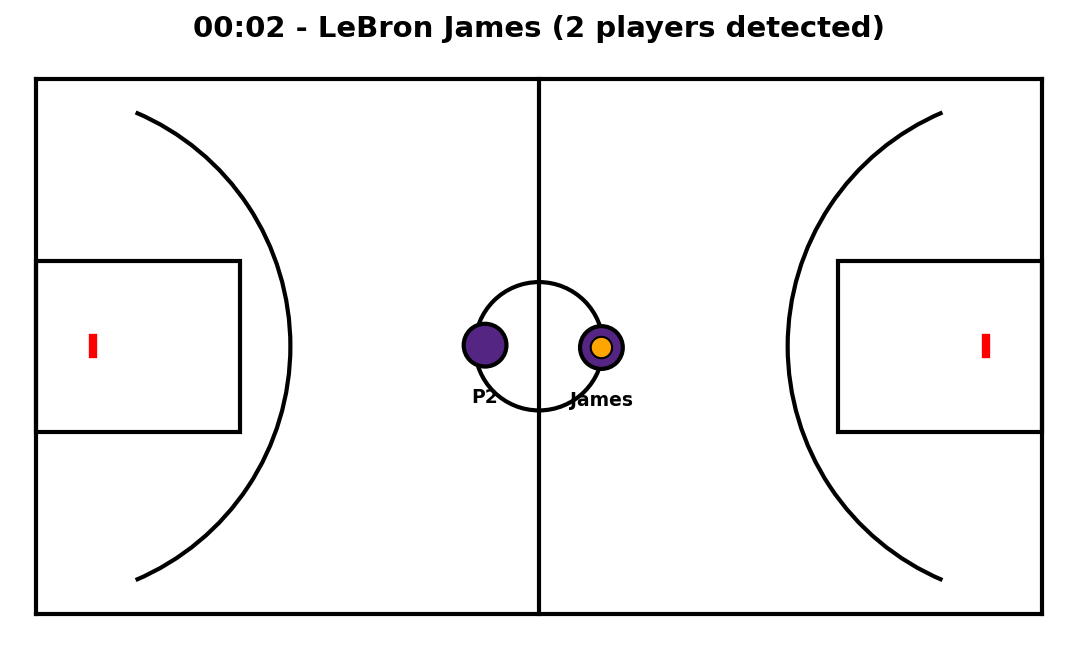


🎥 Video Clip:



────────────────────────────────────────────────────────────
Verification 2/3
────────────────────────────────────────────────────────────
⏰ Timestamp: 01:25
💬 Commentary: It's not Anthony Davis and LeBron James

✓ Extracted 300 frames (10s) → task2_outputs\video_clips\LeBron_James_01_25.mp4
🔍 Running YOLO detection across multiple frames...
✓ Detected 22 unique players across 60 frames at 01:25
✓ Using YOLO-detected positions for 10 players
Saved diagram to task2_outputs\diagrams\LeBron_James_01_25.png

📊 Bird's Eye View:


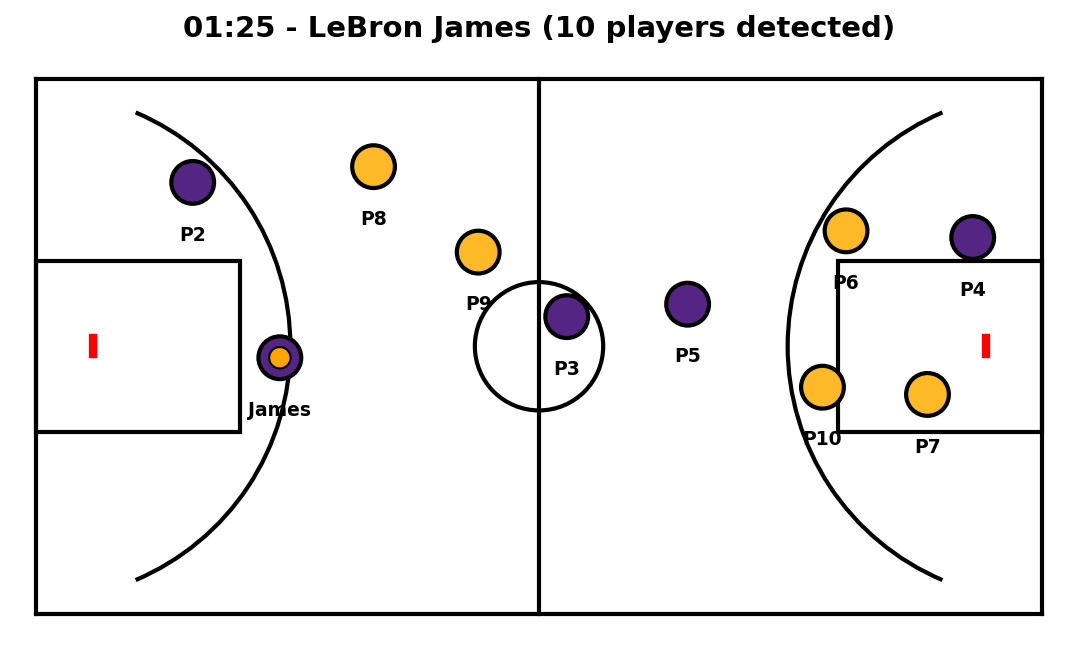


🎥 Video Clip:



────────────────────────────────────────────────────────────
Verification 3/3
────────────────────────────────────────────────────────────
⏰ Timestamp: 03:00
💬 Commentary: without Anthony Davis and LeBron James,

✓ Extracted 300 frames (10s) → task2_outputs\video_clips\LeBron_James_03_00.mp4
🔍 Running YOLO detection across multiple frames...
✓ Detected 13 unique players across 60 frames at 03:00
✓ Using YOLO-detected positions for 10 players
Saved diagram to task2_outputs\diagrams\LeBron_James_03_00.png

📊 Bird's Eye View:


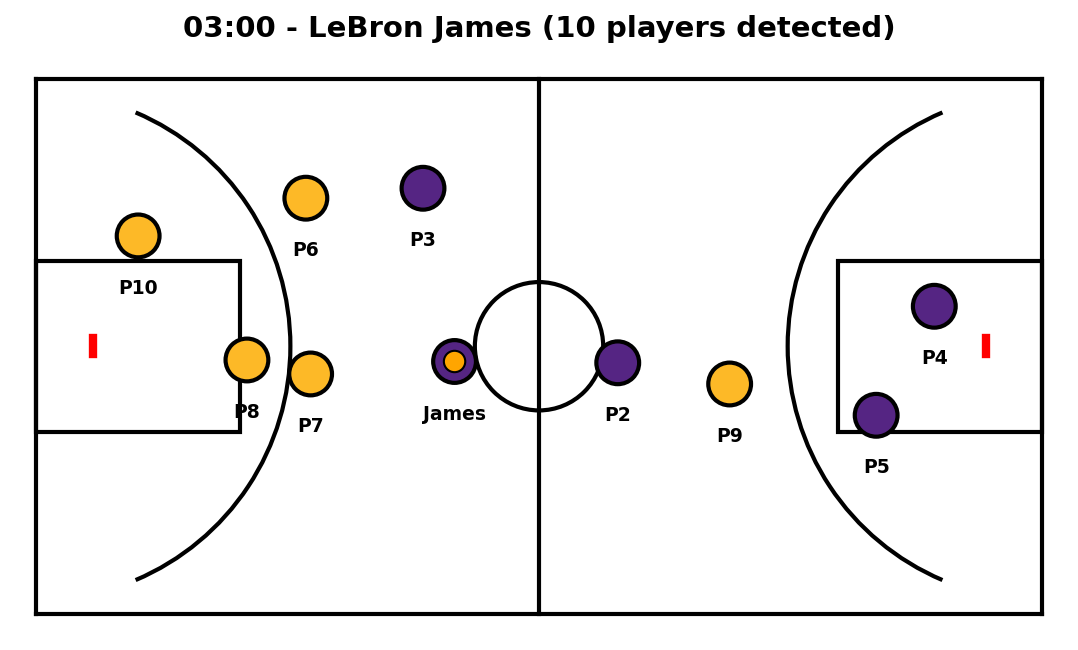


🎥 Video Clip:



✓ Analysis Complete
  - Commentary mentions: 6
  - Video clips created: 3
  - Diagrams created: 3
  - Output directory: task2_outputs
📂 Saved Files:
  📹 LeBron_James_00_02.mp4
  📹 LeBron_James_01_25.mp4
  📹 LeBron_James_03_00.mp4
  📊 LeBron_James_00_02.png
  📊 LeBron_James_01_25.png
  📊 LeBron_James_03_00.png

**Summary**

LeBron James had an impressive performance in this game, showcasing his exceptional skills and adaptability despite playing on a potentially injured right ankle. The commentary highlights several instances of his outstanding defensive plays, aggressive offense, and clutch free throw shooting.

**Detailed Analysis**

* **Defensive Contributions**
	+ At [05:31 - 05:40], LeBron's defensive play allowed Andrew Wiggins to make an impactful shot, but the commentary suggests that LeBron let him off the hook, allowing a potential easy basket to fall. However, this instance is more of a nuanced observation rather than a criticism.
* **Aggressive Offense**
	+ At [10:16 - 10:2

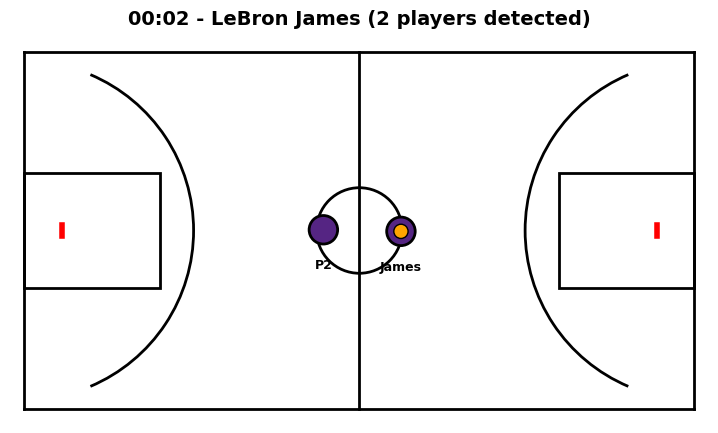

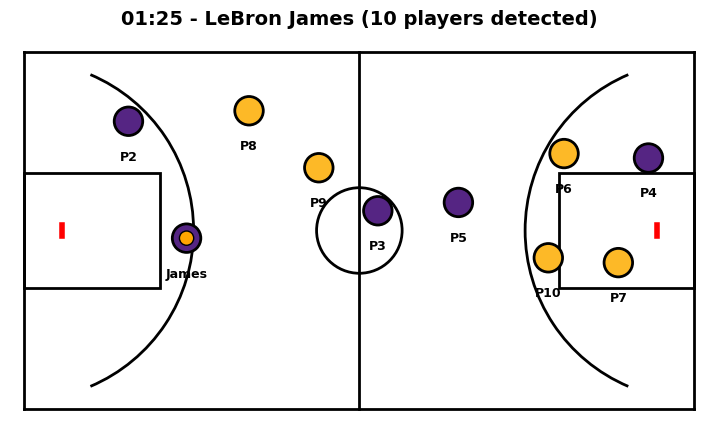

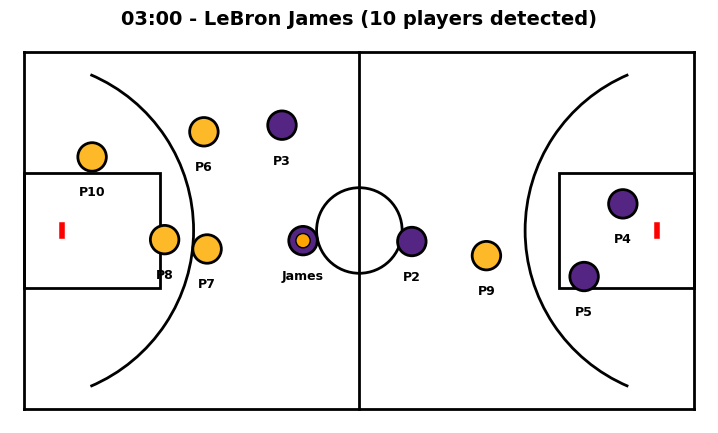

In [249]:
## Example question 1: LeBron James performance
question1 = "How did LeBron James perform in this game?"

print("Question:", question1)
print("" + "="*60)
response1 = qa_system.ask(question1)
print(response1)


In [250]:
## Example question 2: Stephen Curry three-pointers
question2 = "What three-point shots did Stephen Curry make?"

print("Question:", question2)
print("" + "="*60)
response2 = qa_system.ask(question2)
print(response2)


Question: What three-point shots did Stephen Curry make?

AUTO-VERIFICATION: Detected query about Stephen Curry


ANALYZING: Stephen Curry

📝 TASK 1: Commentary-Based Analysis
--------------------------------------------------------------------------------
❌ No mentions of Stephen Curry found in commentary
**Summary**

Stephen Curry made two three-point shots in the commentary context provided. The first attempt was off-marks for the rebound at [09:18 - 09:28], while the second successful shot came from behind the three-point line at an unspecified time, but it's clear he had struggled with his three-point attempts throughout the game.

**Detailed Analysis**

- **First Attempt (Off-Mark)**
At [09:18 - 09:28], Curry launched a three-pointer against Schroeder. The commentator mentioned that Curry was "it's about him" and that Warriors lead by six, indicating he was trying to make an impact. Unfortunately, the shot came up short, resulting in a rebound for the Lakers.

- **Second Attempt 

In [251]:
## Example question 3: Anthony Davis scoring
question3 = "How many points did Anthony Davis score?"

print("Question:", question3)
print("" + "="*60)
response3 = qa_system.ask(question3)
print(response3)


Question: How many points did Anthony Davis score?

AUTO-VERIFICATION: Detected query about Anthony Davis


ANALYZING: Anthony Davis

📝 TASK 1: Commentary-Based Analysis
--------------------------------------------------------------------------------
✓ Found 0 relevant commentary mentions


🎥 TASK 2: Video Verification with YOLO Player Detection
--------------------------------------------------------------------------------
📁 Saving outputs to: task2_outputs
  - Video clips: task2_outputs\video_clips
  - Diagrams: task2_outputs\diagrams

✓ Analysis Complete
  - Commentary mentions: 0
  - Video clips created: 0
  - Diagrams created: 0
  - Output directory: task2_outputs
📂 Saved Files:
  📹 Jordan_Bell_09_07.mp4
  📹 LeBron_James_00_02.mp4
  📹 LeBron_James_01_25.mp4
  📹 LeBron_James_03_00.mp4
  📊 Jordan_Bell_09_07.png
  📊 LeBron_James_00_02.png
  📊 LeBron_James_01_25.png
  📊 LeBron_James_03_00.png

**Summary**

In the provided commentary, Anthony Davis's performance is mentioned several t


Basketball Commentary Analysis System

Ask questions about the game. Type 'quit' to exit.

Question: How many rebounds did jordan bell get this game?

Analyzing...


AUTO-VERIFICATION: Detected query about Jordan Bell


ANALYZING: Jordan Bell

📝 TASK 1: Commentary-Based Analysis
--------------------------------------------------------------------------------
✓ Found 1 relevant commentary mentions

1. [09:07] without Jordan Bell.

🎥 TASK 2: Video Verification with YOLO Player Detection
--------------------------------------------------------------------------------
📁 Saving outputs to: task2_outputs
  - Video clips: task2_outputs\video_clips
  - Diagrams: task2_outputs\diagrams

────────────────────────────────────────────────────────────
Verification 1/1
────────────────────────────────────────────────────────────
⏰ Timestamp: 09:07
💬 Commentary: without Jordan Bell.

✓ Extracted 300 frames (10s) → task2_outputs\video_clips\Jordan_Bell_09_07.mp4
🔍 Running YOLO detection across multipl

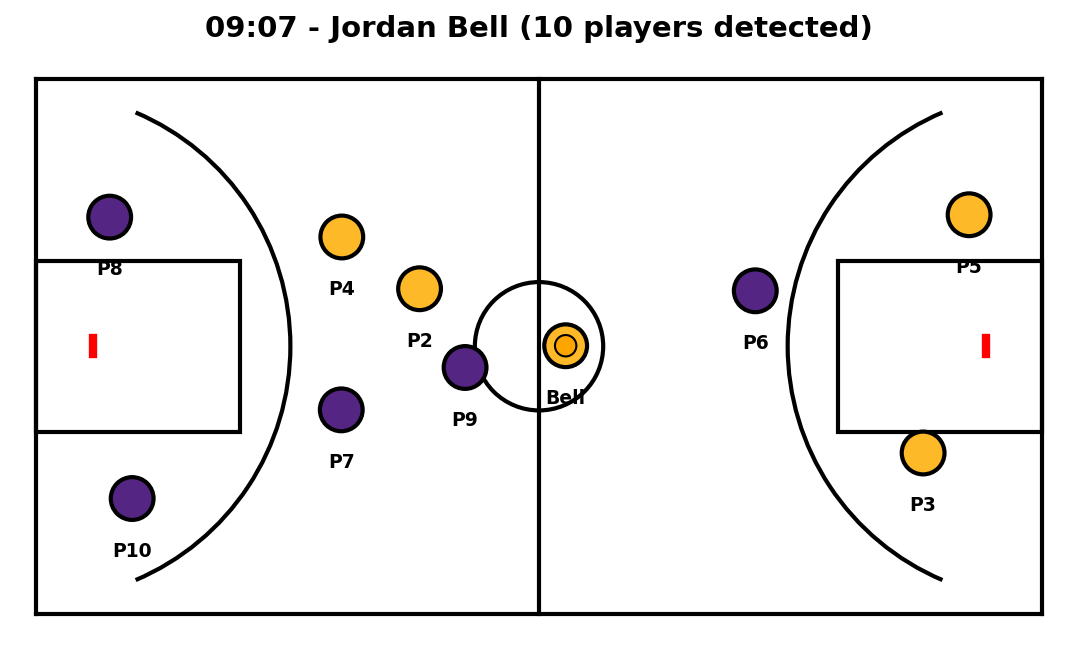


🎥 Video Clip:



✓ Analysis Complete
  - Commentary mentions: 1
  - Video clips created: 1
  - Diagrams created: 1
  - Output directory: task2_outputs
📂 Saved Files:
  📹 LeBron_James_03_00.mp4
  📊 LeBron_James_03_00.png


------------------------------------------------------------
ANALYSIS:
------------------------------------------------------------
**Summary:**
The commentary highlights several players' performance in this basketball game, including Jordan Bell's rebounding efforts. Although Bell's rebounds are not explicitly mentioned by name or quantity, we can infer his performance based on the context.

**Detailed Analysis:**

Jordan Bell is mentioned indirectly through his teammate Andre Drummond, who is described as "one of the premier elite rebounders in the game" (07:40 - 07:49). This implies that Bell contributes to the team's rebounding efforts. However, we don't have a specific timestamp referencing Bell's rebounds.

**Rebound Analysis for Jordan Bell:**

Unfortunately, there are no time

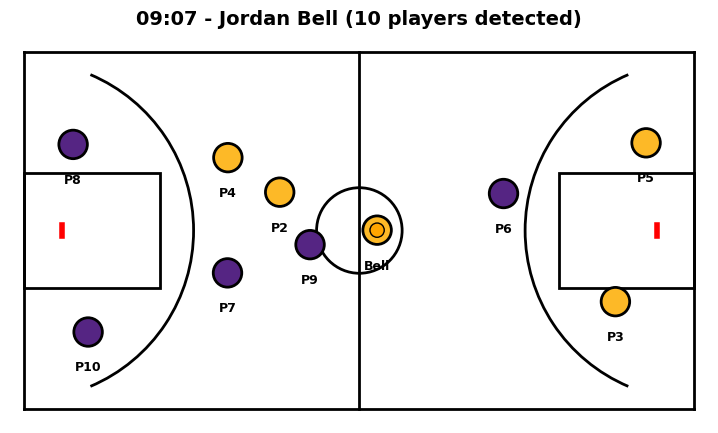

In [252]:
## Implementation of the interactive chat
qa_system.interactive_chat()

In [253]:
class BasketballCourtDiagram:
    """Create bird's-eye view diagrams of basketball court positioning"""
    
    def __init__(self, figsize=(10, 5)):
        self.figsize = figsize
        self.court_length = 94  # NBA court length in feet
        self.court_width = 50   # NBA court width in feet
    
    def create_court(self, ax=None):
        """Draw a basketball court"""
        if ax is None:
            fig, ax = plt.subplots(figsize=self.figsize)
        
        ## Court outline
        ax.plot([0, 0], [0, self.court_width], 'k-', linewidth=2)
        ax.plot([0, self.court_length], [0, 0], 'k-', linewidth=2)
        ax.plot([self.court_length, self.court_length], [0, self.court_width], 'k-', linewidth=2)
        ax.plot([0, self.court_length], [self.court_width, self.court_width], 'k-', linewidth=2)
        
        ## Half court line
        ax.plot([self.court_length/2, self.court_length/2], [0, self.court_width], 'k-', linewidth=2)
        
        ## Center circle
        center_circle = patches.Circle((self.court_length/2, self.court_width/2), 6, 
                                       fill=False, edgecolor='black', linewidth=2)
        ax.add_patch(center_circle)
        
        ## Three-point arcs (simplified)
        left_arc = patches.Arc((0, self.court_width/2), 47.5, 47.5, angle=0, 
                               theta1=-67, theta2=67, edgecolor='black', linewidth=2)
        right_arc = patches.Arc((self.court_length, self.court_width/2), 47.5, 47.5, angle=0,
                                theta1=113, theta2=247, edgecolor='black', linewidth=2)
        ax.add_patch(left_arc)
        ax.add_patch(right_arc)
        
        ## Paint/key areas
        left_key = patches.Rectangle((0, 17), 19, 16, fill=False, edgecolor='black', linewidth=2)
        right_key = patches.Rectangle((75, 17), 19, 16, fill=False, edgecolor='black', linewidth=2)
        ax.add_patch(left_key)
        ax.add_patch(right_key)
        
        ## Baskets
        ax.plot([5.25, 5.25], [self.court_width/2 - 0.75, self.court_width/2 + 0.75], 'r-', linewidth=4)
        ax.plot([self.court_length - 5.25, self.court_length - 5.25], 
                [self.court_width/2 - 0.75, self.court_width/2 + 0.75], 'r-', linewidth=4)
        
        ax.set_xlim(-2, self.court_length + 2)
        ax.set_ylim(-2, self.court_width + 2)
        ax.set_aspect('equal')
        ax.axis('off')
        
        return ax
    
    def add_player(self, ax, x, y, label, color='blue', with_ball=False):
        """Add a player marker to the court"""
        ## Player circle
        player = patches.Circle((x, y), 2, facecolor=color, edgecolor='black', linewidth=2)
        ax.add_patch(player)
        
        ## Player label
        ax.text(x, y-4, label, ha='center', va='top', fontsize=9, fontweight='bold')
        
        ## Ball indicator
        if with_ball:
            ball = patches.Circle((x, y), 1, facecolor='orange', edgecolor='black', linewidth=1)
            ax.add_patch(ball)
    
    def add_movement_arrow(self, ax, x1, y1, x2, y2, color='blue'):
        """Add arrow showing player movement"""
        ax.arrow(x1, y1, x2-x1, y2-y1, head_width=1.5, head_length=1, 
                fc=color, ec=color, linewidth=2, alpha=0.6)
    
    def create_diagram(self, players: List[Dict], title: str = "", save_path: str = None):
        """
        Create a complete court diagram with players
        
        players: List of dicts with keys: x, y, label, color, has_ball, movement_to (optional)
        """
        fig, ax = plt.subplots(figsize=self.figsize)
        self.create_court(ax)
        
        for player in players:
            x = player.get('x', 0)
            y = player.get('y', 0)
            label = player.get('label', '')
            color = player.get('color', 'blue')
            has_ball = player.get('has_ball', False)
            
            self.add_player(ax, x, y, label, color, has_ball)
            
            ## Add movement arrow if specified
            if 'movement_to' in player:
                x2, y2 = player['movement_to']
                self.add_movement_arrow(ax, x, y, x2, y2, color)
        
        if title:
            ax.set_title(title, fontsize=14, fontweight='bold', pad=10)
        
        if save_path:
            plt.savefig(save_path, dpi=150, bbox_inches='tight')
            print(f"Saved diagram to {save_path}")
        
        return fig, ax

In [254]:
import cv2
import base64
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path
from typing import List, Dict, Tuple
import numpy as np
from PIL import Image
from io import BytesIO

## Create output directory for Task 2
TASK2_OUTPUT = Path("task2_outputs")
TASK2_OUTPUT.mkdir(exist_ok=True)

print("✓ Task 2 imports and output directory ready")
from ultralytics import YOLO
import numpy as np

print("Initializing YOLO model for player detection...")
try:
    yolo_model = YOLO('yolov8n.pt')
    print("✓ YOLO model loaded")
except Exception as e:
    print(f"⚠️ YOLO model not loaded: {e}")
    yolo_model = None


✓ Task 2 imports and output directory ready
Initializing YOLO model for player detection...
✓ YOLO model loaded
